# Transforms and the full CUDA training path
Start with a small aligned image, categorical label and validity mask. Declare
what each array means, inspect CPU transforms, then run a pinned DataLoader
through `CudaLoader` and a model/optimizer step entirely on the GPU.

The synthetic objects make spatial correspondence easy to see and require no
remote data. This notebook needs NumPy, Pillow, PyTorch, compiled CPU extensions,
and a CUDA build/device for its final section.


In [1]:
from pathlib import Path
import os

import numpy as np
from _display import panel
from vc_reader import load
from vc_reader.reader import MemoryCache
CACHE = Path(os.environ.get('VC_EXAMPLE_CACHE', '/tmp/vc-reader-notebooks'))
METADATA = os.environ.get('VC_EXAMPLE_METADATA')  # optional local snapshot
options = dict(cache_dir=CACHE, threads=1,
               memory_cache=MemoryCache(64 << 20))


In [2]:
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

torch.manual_seed(7)
torch.set_num_threads(2)
DEVICE = torch.device(os.environ.get('VC_EXAMPLE_DEVICE', 'cuda' if torch.cuda.is_available() else 'cpu'))
print('Training device:', DEVICE)


Training device: cuda


## 1. Construct aligned channel-first arrays


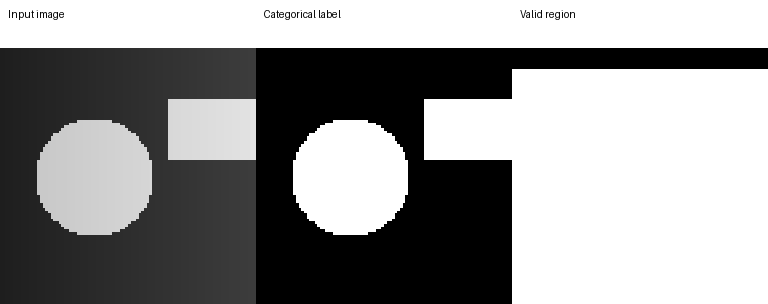

In [3]:
from vc_reader import transforms as A

y, x = np.indices((96, 96), dtype=np.float32)
label = (((x-35)**2 + (y-48)**2 < 22**2) | ((x > 62) & (y > 18) & (y < 42))).astype(np.uint8)[None]
image = np.clip(.12 + .65*label.astype(np.float32) + .12*x[None]/96, 0, 1)
valid = np.ones_like(label, dtype=bool)
valid[:, :8] = False
sample = dict(image=image, label=label, valid=valid)
display(panel([('Input image', image[0]), ('Categorical label', label[0]), ('Valid region', valid[0])]))


## 2. Declare semantics and compose transformations
All spatial transforms use the same geometry for every declared target. `Image`
receives normalization and intensity changes; `Label` uses categorical sampling;
`ValidMask` tracks support. Seeds make an individual call reproducible.

For other data use `ScalarField` for continuous values, or `VectorField`,
`NormalField` and `CoordinateField` with their component/frame declarations.
For volumes supply `(C,Z,Y,X)` arrays and 3D spatial parameters.


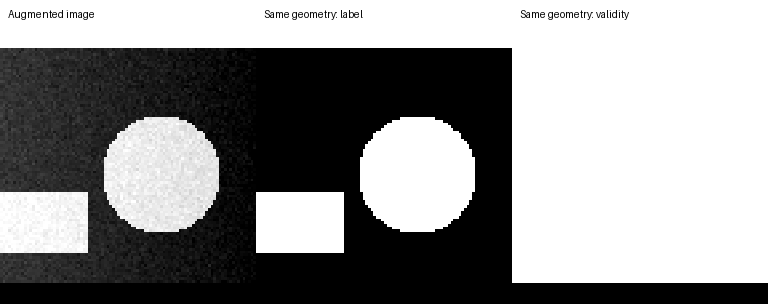

In [4]:
targets = {'image': A.Image(valid='valid'), 'label': A.Label(), 'valid': A.ValidMask()}
transforms = [A.Normalize('minmax'), A.Flip(axes='yx', p=1),
              A.Gamma((.8, 1.2)), A.GaussianNoise(std=.03)]
cpu_pipeline = A.Pipeline(transforms, targets=targets, backend='cpu')
transformed = cpu_pipeline(sample, seed=123)
repeated = cpu_pipeline(sample, seed=123)
for key in sample:
    np.testing.assert_array_equal(transformed[key], repeated[key])
assert set(np.unique(transformed['label'])) <= {0, 1}
display(panel([('Transformed image', transformed['image'][0]),
               ('Same geometry: label', transformed['label'][0]),
               ('Same geometry: validity', transformed['valid'][0])]))


## 3. Wrap a CPU DataLoader with CudaLoader
The Dataset returns CPU arrays. Default collation adds B to make BCHW;
`pin_memory=True` prepares host buffers for transfer. `CudaLoader` uploads a
batch, transforms on its private CUDA stream, and yields ordinary device tensors.
Only declared targets move; `index` remains CPU metadata.

This small notebook uses no worker processes. In an importable training program,
use spawn workers with process-local readers. CUDA execution stays in the main
training process. The final section is explicitly skipped on a CPU-only machine.


CUDA pipeline available: True
Epoch 1 last batch loss 0.7224065065383911
Epoch 2 last batch loss 0.7190631628036499
Targets on cuda:0 ; index metadata on cpu


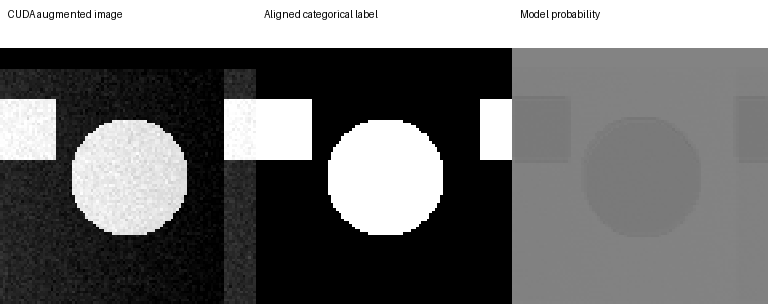

In [5]:
CUDA_AVAILABLE = torch.cuda.is_available()
if CUDA_AVAILABLE:
    from vc_reader.cuda import is_available
    CUDA_AVAILABLE = is_available()
print('CUDA pipeline available:', CUDA_AVAILABLE)

class Shapes(Dataset):
    def __len__(self):
        return 8

    def __getitem__(self, index):
        # uint8 is uploaded compactly, then Image is promoted to float32 on device.
        return {'image': (np.roll(image, index*2, axis=2)*255).astype(np.uint8),
                'label': np.roll(label, index*2, axis=2).copy(),
                'valid': np.roll(valid, index*2, axis=2).copy(), 'index': index}

if CUDA_AVAILABLE:
    from vc_reader.torch import CudaLoader
    cpu_loader = DataLoader(Shapes(), batch_size=2, num_workers=0, pin_memory=True)
    gpu_pipeline = A.Pipeline(transforms, targets=targets, backend='cuda')
    cuda_loader = CudaLoader(cpu_loader, gpu_pipeline, seed=123, prefetch=True)
    model = nn.Sequential(nn.Conv2d(1, 8, 3, padding=1), nn.ReLU(), nn.Conv2d(8, 1, 1)).to('cuda')
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    loss_fn = nn.BCEWithLogitsLoss(reduction='none')
    for epoch in range(2):
        cuda_loader.set_epoch(epoch)
        iterator = iter(cuda_loader)
        try:
            for batch in iterator:
                assert batch['image'].is_cuda and batch['label'].is_cuda and batch['valid'].is_cuda
                logits = model(batch['image'])
                loss = loss_fn(logits, batch['label'].float())[batch['valid']].mean()
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()
            print('Epoch', epoch+1, 'last batch loss', float(loss.detach()))
        finally:
            iterator.close()  # also release pending batches after an early break
    print('Targets on', batch['image'].device, '; index metadata on', batch['index'].device)
    display(panel([('CUDA transformed image', batch['image'][0, 0].cpu().numpy()),
                   ('Aligned categorical label', batch['label'][0, 0].cpu().numpy()),
                   ('Model probability', logits[0, 0].detach().sigmoid().cpu().numpy())]))
else:
    print('CPU examples completed. Run this section with a CUDA build and device for the full pipeline.')


## Resident batches and seeds
For tensors already on the GPU, `gpu_pipeline.batch(batch, seeds=[...])` runs the
same batch API without a DataLoader wrapper. Keep one CPU integer seed per sample.
Use `CudaLoader(..., seed_key='seed')` when transform must follow explicit
sample identities; otherwise `set_epoch` changes seeds based on epoch and position.
Only visualization and printed scalar losses above cross back to the CPU.
These tiny shapes demonstrate data flow, not GPU throughput.
